# Домашнее задание: SFT для function calling

Qwen2.5-0.5B-Instruct умеет вызывать функции в формате `<tool_call>`, но наши пять функций умного дома видит
впервые и обращается с ними вольно. Дообучим её целиком (все веса) на диалогах с умным домом
и в конце посмотрим, как она управляет симулятором.

| Блок | Баллы |
|---|---|
| 1. До обучения: генерация через chat template | 1 |
| 2. Данные: разбор примера и роль каждого сообщения | 2 |
| 3. Маска loss: теги `{% generation %}` в шаблоне | 2 |
| 4. Обучение | 3 |
| 5. Оценка на тест-сете (дано) | 0 |
| 6. Агентный цикл | 2 |

Дано и менять не нужно: `smart_home.py` (симулятор и схемы пяти функций), `chat_ui.py` (чат),
`data/` с `train.jsonl`, `validation.jsonl` и `test_cases.jsonl`.
Ячейки для заполнения помечены `YOUR CODE HERE`.

In [1]:
import torch
import os
os.environ["CUDA_VISIBLE_DEVICES"] = "0"
torch.cuda.device_count()

1

## 0. Окружение

Берём Instruct-модель: формат `<tool_call>` и токен конца реплики `<|im_end|>` она уже знает,
учить будем поведению с конкретными функциями.

In [3]:
import gc
import hashlib
import json
import os
import re
import shutil
import subprocess
from datetime import datetime, timezone
from importlib.metadata import version
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd
import torch
import yaml
from datasets import Dataset
from IPython.display import display
from transformers import AutoModelForCausalLM, AutoTokenizer, PreTrainedModel, PreTrainedTokenizerBase, set_seed
from trl import SFTConfig, SFTTrainer

from chat_ui import launch_chat
from smart_home import BASELINE_PROMPTS, SMART_HOME_TOOLS, SYSTEM_PROMPT, SmartHome

SEED = 42
ROOT = Path(os.environ.get("HW3_ROOT", "/gpfs/fs_2/SHARED/adzhiev/hse_hw3"))
RUN_NAME = os.environ.get("HW3_RUN_NAME", "full_sft_qwen25_05b_")
assert RUN_NAME and Path(RUN_NAME).name == RUN_NAME, "invalid `RUN_NAME`"
DATA_DIR = ROOT / "data"
MODEL_NAME = str(ROOT / "models/Qwen2.5-0.5B-Instruct")
RUN_DIR = ROOT / "artifacts" / RUN_NAME
OUTPUT_DIR = RUN_DIR / "checkpoints"
METRICS_DIR = RUN_DIR / "metrics"
MAX_LENGTH = 2048

assert not (RUN_DIR / "config.yaml").exists(), "choose a new `HW3_RUN_NAME` to preserve previous artifacts"
assert torch.cuda.is_available(), "a CUDA device is required"
RUN_DIR.mkdir(parents=True, exist_ok=True)
METRICS_DIR.mkdir(exist_ok=True)
Path("outputs").mkdir(exist_ok=True)
set_seed(SEED)
torch.set_num_threads(8)
pd.set_option("display.max_colwidth", 200)

run_config = {
    "run_name": RUN_NAME,
    "base_model": "Qwen/Qwen2.5-0.5B-Instruct",
    "model_path": MODEL_NAME,
    "data_dir": str(DATA_DIR),
    "seed": SEED,
    "max_length": MAX_LENGTH,
    "device": torch.cuda.get_device_name(),
    "packages": {name: version(name) for name in (
        "torch", "transformers", "trl", "datasets", "accelerate", "pandas", "matplotlib"
    )},
    "sha256": {},
}
for path in [*sorted(DATA_DIR.glob("*.jsonl")), Path(MODEL_NAME) / "model.safetensors"]:
    with path.open("rb") as stream:
        run_config["sha256"][path.name] = hashlib.file_digest(stream, "sha256").hexdigest()


def save_provenance(directory: Path) -> None:
    directory.mkdir(parents=True, exist_ok=True)
    directory.joinpath("config.yaml").write_text(yaml.safe_dump(run_config, sort_keys=False))
    command = ["git", "-c", "core.fsmonitor=false", "-c", "core.hooksPath=/dev/null"]
    def git(*arguments: str) -> str:
        return subprocess.check_output([*command, *arguments], text=True).strip()
    metadata = {
        "repo_path": git("rev-parse", "--show-toplevel"),
        "branch": git("branch", "--show-current"),
        "commit": git("rev-parse", "HEAD"),
        "dirty_tree": bool(git("status", "--porcelain")),
        "saved_at_utc": datetime.now(timezone.utc).isoformat(),
    }
    directory.joinpath("git_meta.txt").write_text("".join(f"{key}: {value}\n" for key, value in metadata.items()))


save_provenance(RUN_DIR)
tokenizer = AutoTokenizer.from_pretrained(MODEL_NAME, local_files_only=True)
model = AutoModelForCausalLM.from_pretrained(
    MODEL_NAME, dtype=torch.bfloat16, attn_implementation="sdpa", local_files_only=True,
).to("cuda")
print(f"run: {RUN_NAME}; device: {torch.cuda.get_device_name()}; parameters: {model.num_parameters():,}")

run: full_sft_qwen25_05b_; device: NVIDIA H100 80GB HBM3; parameters: 494,032,768


## 1. До обучения · 1 балл

Функция для модели — это JSON Schema: имя, описание, аргументы с типами и ограничениями.
Схемы передаются в `apply_chat_template` параметром `tools`: шаблон вставит их в system-реплику
и объяснит модели формат ответа `<tool_call>`. Посмотрим, что именно получает модель на вход.

In [4]:
print(json.dumps(SMART_HOME_TOOLS[0], ensure_ascii=False, indent=2))
print("=" * 80)
messages = [
    {"role": "system", "content": SYSTEM_PROMPT},
    {"role": "user", "content": "Turn on the kitchen light."},
]
print(tokenizer.apply_chat_template(messages, tools=SMART_HOME_TOOLS, tokenize=False, add_generation_prompt=True))

{
  "type": "function",
  "function": {
    "name": "turn_light",
    "description": "Switch a room light on or off. Ask for the room if unknown.",
    "parameters": {
      "type": "object",
      "properties": {
        "room": {
          "type": "string",
          "enum": [
            "kitchen",
            "bedroom",
            "living_room"
          ]
        },
        "state": {
          "type": "string",
          "enum": [
            "on",
            "off"
          ]
        }
      },
      "required": [
        "room",
        "state"
      ],
      "additionalProperties": false
    }
  }
}
<|im_start|>system
You are a smart home assistant. Use only the provided tools. Do not invent missing arguments or claim actions without tool results. Ask for clarification when needed.

# Tools

You may call one or more functions to assist with the user query.

You are provided with function signatures within <tools></tools> XML tags:
<tools>
{"type": "function", "function": {"n

**Задание (1 балл).** Напишите `generate`: сообщения и схемы функций проходят через `apply_chat_template`
с `add_generation_prompt=True`, декодирование жадное, стоп на `<|im_end|>` (это `eos_token` токенизатора).
Верните только новые токены, без спецтокенов. Эта функция используется во всех следующих блоках.

In [5]:
@torch.inference_mode()
def generate(
    model: PreTrainedModel,
    tokenizer: PreTrainedTokenizerBase,
    messages: list[dict],
    tools: list[dict],
    max_new_tokens: int = 256,
) -> str:
    model.eval()
    inputs = tokenizer.apply_chat_template(
        messages, tools=tools, tokenize=True, add_generation_prompt=True,
        return_tensors="pt", return_dict=True,
    ).to(model.device)
    output = model.generate(
        **inputs, max_new_tokens=max_new_tokens, do_sample=False,
        eos_token_id=tokenizer.eos_token_id, pad_token_id=tokenizer.pad_token_id,
        temperature=None, top_p=None, top_k=None,
    )
    return tokenizer.decode(output[0, inputs["input_ids"].shape[1]:], skip_special_tokens=True)


def answer(model: PreTrainedModel, tokenizer: PreTrainedTokenizerBase, prompt: str) -> str:
    messages = [{"role": "system", "content": SYSTEM_PROMPT}, {"role": "user", "content": prompt}]
    return generate(model, tokenizer, messages, SMART_HOME_TOOLS)

Формат модель знает, поэтому простые запросы отработает правильно. Смотрите на сложные: «Open the garage» —
модель подставляет в `turn_light` комнату `garage`, которой нет в схеме; «Turn off all lights» — придумывает
`room: "all"` вместо трёх вызовов; «Turn on the light» — выбирает комнату сама вместо уточняющего вопроса.
Запомним её ответы на десять запросов, после обучения сравним.

In [6]:
comparison = pd.DataFrame({"prompt": BASELINE_PROMPTS})
comparison["base"] = [answer(model, tokenizer, prompt) for prompt in BASELINE_PROMPTS]
display(comparison)

,prompt,base
0,Turn on the kitchen light.,"<tool_call>\n{""name"": ""turn_light"", ""arguments"": {""room"": ""kitchen"", ""state"": ""on""}}\n</tool_call>"
1,Set the bedroom to 23 degrees.,"<tool_call>\n{""name"": ""set_temperature"", ""arguments"": {""room"": ""bedroom"", ""value"": 23}}\n</tool_call>"
2,What is the state of the living room?,"<tool_call>\n{""name"": ""get_room_state"", ""arguments"": {""room"": ""living_room""}}\n</tool_call>"
3,Add two cartons of milk to my shopping list.,"<tool_call>\n{""name"": ""add_to_shopping_list"", ""arguments"": {""item"": ""milk"", ""quantity"": 2}}\n</tool_call>"
4,Set a 10-minute timer labeled pasta.,"<tool_call>\n{""name"": ""set_timer"", ""arguments"": {""minutes"": 10, ""label"": ""pasta""}}\n</tool_call>"
5,Turn off the bedroom light and set its temperature to 20 degrees.,"<tool_call>\n{""name"": ""turn_light"", ""arguments"": {""room"": ""bedroom"", ""state"": ""off""}}\n</tool_call>\n<tool_call>\n{""name"": ""set_temperature"", ""arguments"": {""room"": ""bedroom"", ""value"": 20}}\n</tool..."
6,Turn off all lights.,"<tool_call>\n{""name"": ""turn_light"", ""arguments"": {""room"": ""all"", ""state"": ""off""}}\n</tool_call>"
7,Hello!,How can I help you today?
8,Open the garage.,"<tool_call>\n{""name"": ""turn_light"", ""arguments"": {""room"": ""garage"", ""state"": ""on""}}\n</tool_call>"
9,Turn on the light.,"<tool_call>\n{""name"": ""turn_light"", ""arguments"": {""room"": ""living_room"", ""state"": ""on""}}\n</tool_call>"


## 2. Данные · 2 балла

Чтобы модель вызывала функции, покажем ей диалоги, где это делается правильно.
Одна строка JSONL — один диалог: `messages` и `tools`. Вызов функции — поле `tool_calls`
у реплики assistant, результат функции — отдельное сообщение с ролью `tool`.

In [7]:
def read_jsonl(path: str | Path) -> list[dict]:
    return [json.loads(line) for line in Path(path).read_text().splitlines() if line.strip()]


def show_dialog(messages: list[dict]) -> None:
    for message in messages:
        print(f"[{message['role']}] {message.get('content', '')}")
        for call in message.get("tool_calls") or []:
            arguments = json.dumps(call["function"]["arguments"], ensure_ascii=False)
            print(f"    -> {call['function']['name']}({arguments})")


train_rows = read_jsonl(DATA_DIR / "train.jsonl")
validation_rows = read_jsonl(DATA_DIR / "validation.jsonl")
assert len({row["scenario_id"] for row in train_rows} & {row["scenario_id"] for row in validation_rows}) == 0
print(f"train: {len(train_rows)}, validation: {len(validation_rows)}\n")

example = next(row for row in train_rows if any(m.get("tool_calls") for m in row["messages"]))
show_dialog(example["messages"])

train: 831, validation: 91

[system] You are a smart home assistant. Use only the provided tools. Do not invent missing arguments or claim actions without tool results. Ask for clarification when needed.
[user] Сделай в гостиной 40 градусов, гости мерзнут
[assistant] Выше 30 градусов поставить нельзя, диапазон 16-30. Поставить в гостиной 30?
[user] Хорошо, тогда максимум
[assistant] 
    -> set_temperature({"room": "living_room", "value": 30})
[tool] {"room": "living_room", "light": "off", "temperature": 30}
[assistant] Готово, в гостиной теперь 30 градусов.


В данных четыре типа диалогов. Примеры без вызова — не балласт: это единственное место, где модель видит,
что на неподдерживаемый запрос («открой гараж», «какая погода») нужно ответить отказом, а не подобрать
ближайшую функцию.

In [8]:
def scenario_type(row):
    calls_per_message = [len(m.get("tool_calls") or []) for m in row["messages"]]
    if sum(calls_per_message) == 0:
        return "no_call"
    if sum(n > 0 for n in calls_per_message) > 1:
        return "multi_turn"
    return "parallel_calls" if max(calls_per_message) > 1 else "single_call"


pd.DataFrame({
    "train": pd.Series([scenario_type(row) for row in train_rows]).value_counts(),
    "validation": pd.Series([scenario_type(row) for row in validation_rows]).value_counts(),
})

,train,validation
multi_turn,219,22
no_call,144,16
parallel_calls,145,15
single_call,323,38


Тот же диалог после шаблона — ровно такой текст модель увидит на обучении. `tool_calls` стали блоками
`<tool_call>` внутри реплики assistant, а результат функции — блоком `<tool_response>` внутри реплики
**user**: для модели это входящая информация, как и вопрос пользователя.

In [9]:
print(tokenizer.apply_chat_template(example["messages"], tools=example["tools"], tokenize=False))

<|im_start|>system
You are a smart home assistant. Use only the provided tools. Do not invent missing arguments or claim actions without tool results. Ask for clarification when needed.

# Tools

You may call one or more functions to assist with the user query.

You are provided with function signatures within <tools></tools> XML tags:
<tools>
{"type": "function", "function": {"name": "turn_light", "description": "Switch a room light on or off. Ask for the room if unknown.", "parameters": {"type": "object", "properties": {"room": {"type": "string", "enum": ["kitchen", "bedroom", "living_room"]}, "state": {"type": "string", "enum": ["on", "off"]}}, "required": ["room", "state"], "additionalProperties": false}}}
{"type": "function", "function": {"name": "set_temperature", "description": "Set an absolute room temperature in Celsius. For relative changes, obtain the current temperature first.", "parameters": {"type": "object", "properties": {"room": {"type": "string", "enum": ["kitchen", "

### Что в данных

`system` задаёт правила, `tools` описывает функции, `user` передаёт запрос. `assistant` отвечает
или вызывает функции через `tool_calls`, а `tool` возвращает результат симулятора.

В данных результат имеет роль `tool`, а шаблон Qwen показывает его модели как `<tool_response>`
внутри реплики `user`. Модель читает результат, но не учится предсказывать состояние устройств.

| Сценарий | Обучение | Валидация | Чему учит |
|---|---:|---:|---|
| `single_call` | 323 | 38 | Выбрать одну функцию и аргументы, ответить по результату. |
| `parallel_calls` | 145 | 15 | Сделать несколько независимых вызовов за ход. |
| `multi_turn` | 219 | 22 | Учитывать историю и результаты функций. |
| `no_call` | 144 | 16 | Ответить без вызова, уточнить запрос или отказать. |

Категории `scenario_type` могут пересекаться. `scenario_id` в обучении и валидации не пересекаются;
тестовые данные используются только для итоговой оценки.

## 3. Маска loss · 2 балла

В тексте выше модель должна учиться только своим репликам: тексту, `<tool_call>` и `<|im_end|>`.
Запрос пользователя и результат функции она читает, но не предсказывает — у этих токенов label `-100`.
За это в TRL отвечает `assistant_only_loss=True`, а маску он строит по тегам
`{% generation %}…{% endgeneration %}` в chat template. В нативном шаблоне Qwen их нет.

In [10]:
NATIVE_TEMPLATE = tokenizer.chat_template
print(NATIVE_TEMPLATE)

{%- if tools %}
    {{- '<|im_start|>system\n' }}
    {%- if messages[0]['role'] == 'system' %}
        {{- messages[0]['content'] }}
    {%- else %}
        {{- 'You are Qwen, created by Alibaba Cloud. You are a helpful assistant.' }}
    {%- endif %}
    {{- "\n\n# Tools\n\nYou may call one or more functions to assist with the user query.\n\nYou are provided with function signatures within <tools></tools> XML tags:\n<tools>" }}
    {%- for tool in tools %}
        {{- "\n" }}
        {{- tool | tojson }}
    {%- endfor %}
    {{- "\n</tools>\n\nFor each function call, return a json object with function name and arguments within <tool_call></tool_call> XML tags:\n<tool_call>\n{\"name\": <function-name>, \"arguments\": <args-json-object>}\n</tool_call><|im_end|>\n" }}
{%- else %}
    {%- if messages[0]['role'] == 'system' %}
        {{- '<|im_start|>system\n' + messages[0]['content'] + '<|im_end|>\n' }}
    {%- else %}
        {{- '<|im_start|>system\nYou are Qwen, created by Alibaba C

**Задание (2 балла).** Оберните в `{% generation %}…{% endgeneration %}` вывод реплик assistant — и текст,
и `tool_calls` — и присвойте результат в `tokenizer.chat_template`. Текст, который рендерит шаблон,
меняться не должен: теги влияют только на маску. Ячейка после задания проверит и то, и другое,
и напечатает токены, по которым будет считаться loss.

In [11]:
TRAIN_TEMPLATE = r"""{%- if tools %}
    {{- '<|im_start|>system\n' }}
    {%- if messages[0]['role'] == 'system' %}
        {{- messages[0]['content'] }}
    {%- else %}
        {{- 'You are Qwen, created by Alibaba Cloud. You are a helpful assistant.' }}
    {%- endif %}
    {{- "\n\n# Tools\n\nYou may call one or more functions to assist with the user query.\n\nYou are provided with function signatures within <tools></tools> XML tags:\n<tools>" }}
    {%- for tool in tools %}
        {{- "\n" }}
        {{- tool | tojson }}
    {%- endfor %}
    {{- "\n</tools>\n\nFor each function call, return a json object with function name and arguments within <tool_call></tool_call> XML tags:\n<tool_call>\n{\"name\": <function-name>, \"arguments\": <args-json-object>}\n</tool_call><|im_end|>\n" }}
{%- else %}
    {%- if messages[0]['role'] == 'system' %}
        {{- '<|im_start|>system\n' + messages[0]['content'] + '<|im_end|>\n' }}
    {%- else %}
        {{- '<|im_start|>system\nYou are Qwen, created by Alibaba Cloud. You are a helpful assistant.<|im_end|>\n' }}
    {%- endif %}
{%- endif %}
{%- for message in messages %}
    {%- if (message.role == "user") or (message.role == "system" and not loop.first) %}
        {{- '<|im_start|>' + message.role + '\n' + message.content + '<|im_end|>' + '\n' }}
    {%- elif message.role == "assistant" and not message.tool_calls %}
        {{- '<|im_start|>assistant\n' }}
        {%- generation %}{{- message.content + '<|im_end|>' }}{% endgeneration %}
        {{- '\n' }}
    {%- elif message.role == "assistant" %}
        {{- '<|im_start|>' + message.role }}
        {%- generation %}
        {%- if message.content %}
            {{- '\n' + message.content }}
        {%- endif %}
        {%- for tool_call in message.tool_calls %}
            {%- if tool_call.function is defined %}
                {%- set tool_call = tool_call.function %}
            {%- endif %}
            {{- '\n<tool_call>\n{"name": "' }}
            {{- tool_call.name }}
            {{- '", "arguments": ' }}
            {{- tool_call.arguments | tojson }}
            {{- '}\n</tool_call>' }}
        {%- endfor %}
        {{- '<|im_end|>' }}{% endgeneration %}
        {{- '\n' }}
    {%- elif message.role == "tool" %}
        {%- if (loop.index0 == 0) or (messages[loop.index0 - 1].role != "tool") %}
            {{- '<|im_start|>user' }}
        {%- endif %}
        {{- '\n<tool_response>\n' }}
        {{- message.content }}
        {{- '\n</tool_response>' }}
        {%- if loop.last or (messages[loop.index0 + 1].role != "tool") %}
            {{- '<|im_end|>\n' }}
        {%- endif %}
    {%- endif %}
{%- endfor %}
{%- if add_generation_prompt %}
    {{- '<|im_start|>assistant\n' }}
{%- endif %}
"""
tokenizer.chat_template = TRAIN_TEMPLATE

In [12]:
rendered = tokenizer.apply_chat_template(example["messages"], tools=example["tools"], tokenize=False)
assert rendered == tokenizer.apply_chat_template(
    example["messages"], tools=example["tools"], tokenize=False, chat_template=NATIVE_TEMPLATE
), "generation tags changed the rendered text"

encoded = tokenizer.apply_chat_template(
    example["messages"], tools=example["tools"],
    tokenize=True, return_dict=True, return_assistant_tokens_mask=True,
)
trained = tokenizer.decode([token for token, flag in zip(encoded["input_ids"], encoded["assistant_masks"]) if flag])
assert "<tool_call>" in trained and "<|im_end|>" in trained, "assistant output is missing from the mask"
assert "<tools>" not in trained and "<tool_response>" not in trained, "the mask includes tool context"
print(f"training on {sum(encoded['assistant_masks'])} of {len(encoded['input_ids'])} tokens:\n")
print(trained)

lengths = []
masked_tokens = 0
all_tokens = 0
for row in train_rows + validation_rows:
    native = tokenizer.apply_chat_template(
        row["messages"], tools=row["tools"], tokenize=False, chat_template=NATIVE_TEMPLATE,
    )
    rendered = tokenizer.apply_chat_template(row["messages"], tools=row["tools"], tokenize=False)
    assert rendered == native, row["id"]
    assert tokenizer.apply_chat_template(
        row["messages"], tools=row["tools"], tokenize=False, add_generation_prompt=True,
    ) == tokenizer.apply_chat_template(
        row["messages"], tools=row["tools"], tokenize=False, add_generation_prompt=True,
        chat_template=NATIVE_TEMPLATE,
    ), row["id"]
    encoded = tokenizer.apply_chat_template(
        row["messages"], tools=row["tools"], tokenize=True, return_dict=True,
        return_assistant_tokens_mask=True, tokenizer_kwargs={"return_offsets_mapping": True},
    )
    assistant_messages = [message for message in row["messages"] if message["role"] == "assistant"]
    matches = list(re.finditer(r"<\|im_start\|>assistant(.*?<\|im_end\|>)", rendered, re.DOTALL))
    assert len(matches) == len(assistant_messages)
    spans = [
        (match.start(1) + (0 if message.get("tool_calls") else 1), match.end(1))
        for match, message in zip(matches, assistant_messages)
    ]
    expected = [
        int(end > start and any(start < right and end > left for left, right in spans))
        for start, end in encoded["offset_mapping"]
    ]
    assert encoded["assistant_masks"] == expected, row["id"]
    assert any(expected), row["id"]
    lengths.append(len(encoded["input_ids"]))
    masked_tokens += sum(expected)
    all_tokens += len(expected)
assert max(lengths) <= MAX_LENGTH, "increase `MAX_LENGTH` to avoid losing dialogue targets"
print(f"verified native rendering and assistant-only offsets for {len(lengths)} dialogues")
print(f"maximum length: {max(lengths)}; assistant tokens: {masked_tokens}/{all_tokens} ({masked_tokens/all_tokens:.1%})")

training on 86 of 764 tokens:

Выше 30 градусов поставить нельзя, диапазон 16-30. Поставить в гостиной 30?<|im_end|>
<tool_call>
{"name": "set_temperature", "arguments": {"room": "living_room", "value": 30}}
</tool_call><|im_end|>Готово, в гостиной теперь 30 градусов.<|im_end|>


verified native rendering and assistant-only offsets for 922 dialogues
maximum length: 1285; assistant tokens: 70211/698962 (10.0%)


## 4. Обучение · 3 балла

Данные и маска готовы. `SFTTrainer` сам применит шаблон к `messages` и `tools`, а `assistant_only_loss=True`
возьмёт маску из ваших тегов. Обучаем все веса модели.

In [13]:
def drop_nulls(value):
    if isinstance(value, dict):
        return {key: drop_nulls(item) for key, item in value.items() if item is not None}
    if isinstance(value, list):
        return [drop_nulls(item) for item in value]
    return value


def to_dataset(rows: list[dict]) -> Dataset:
    # Arrow unifies heterogeneous tool schemas; remove the resulting null properties before templating.
    dataset = Dataset.from_list([{"messages": row["messages"], "tools": row["tools"]} for row in rows])
    return dataset.with_transform(lambda batch: {key: [drop_nulls(item) for item in items] for key, items in batch.items()})


train_dataset = to_dataset(train_rows)
validation_dataset = to_dataset(validation_rows)

**Задание (3 балла).** Заполните `SFTConfig`, создайте `SFTTrainer`, обучите модель и сохраните её в `OUTPUT_DIR`
(`trainer.save_model()` сохранит и токенизатор с вашим шаблоном). Ориентир: 3 эпохи на 0.5B — пара минут на A100.

In [14]:
config = SFTConfig(
    output_dir=str(OUTPUT_DIR),
    run_name=RUN_NAME,
    num_train_epochs=3,
    per_device_train_batch_size=8,
    per_device_eval_batch_size=8,
    gradient_accumulation_steps=2,
    learning_rate=5e-5,
    lr_scheduler_type="cosine",
    warmup_ratio=0.05,
    weight_decay=0.01,
    max_grad_norm=1.0,
    max_length=MAX_LENGTH,
    assistant_only_loss=True,
    packing=False,
    bf16=True,
    tf32=True,
    gradient_checkpointing=False,
    optim="adamw_torch_fused",
    eval_strategy="epoch",
    save_strategy="no",
    logging_steps=5,
    logging_first_step=True,
    logging_dir=str(RUN_DIR / "logs"),
    report_to="none",
    disable_tqdm=True,
    seed=SEED,
    data_seed=SEED,
)
run_config["training_args"] = config.to_dict()
run_config["dataset_sizes"] = {"train": len(train_rows), "validation": len(validation_rows)}
save_provenance(RUN_DIR)
trainer = SFTTrainer(
    model=model,
    args=config,
    train_dataset=train_dataset,
    eval_dataset=validation_dataset,
    processing_class=tokenizer,
)
assert all(parameter.requires_grad for parameter in model.parameters()), "all model weights must be trainable"
assert sum(parameter.numel() for parameter in model.parameters() if parameter.requires_grad) == model.num_parameters()

batch = trainer.data_collator([trainer.train_dataset[index] for index in range(2)])
for index in range(2):
    length = len(trainer.train_dataset[index]["input_ids"])
    mask = torch.tensor(trainer.train_dataset[index]["assistant_masks"], dtype=torch.bool)
    assert torch.all(batch["labels"][index, :length][~mask] == -100)
    assert torch.equal(batch["labels"][index, :length][mask], batch["input_ids"][index, :length][mask])
    assert torch.all(batch["labels"][index, length:] == -100)
print("verified actual trainer labels: context and padding are ignored")

initial_metrics = trainer.evaluate()
print(f"initial validation loss: {initial_metrics['eval_loss']:.4f}")
train_result = trainer.train()
save_provenance(OUTPUT_DIR)
trainer.save_model(str(OUTPUT_DIR))
trainer.save_state()
trainer.log_metrics("train", train_result.metrics)
trainer.save_metrics("train", train_result.metrics)
print(f"saved full model and tokenizer: {OUTPUT_DIR}")

Tokenizing train dataset:   0%|          | 0/831 [00:00<?, ? examples/s]

Truncating train dataset:   0%|          | 0/831 [00:00<?, ? examples/s]

Tokenizing eval dataset:   0%|          | 0/91 [00:00<?, ? examples/s]

Truncating eval dataset:   0%|          | 0/91 [00:00<?, ? examples/s]

verified actual trainer labels: context and padding are ignored


The tokenizer has new PAD/BOS/EOS tokens that differ from the model config and generation config. The model config and generation config were aligned accordingly, being updated with the tokenizer's values. Updated tokens: {'bos_token_id': None, 'pad_token_id': 151643}.


{'eval_loss': 0.9212706089019775, 'eval_model_preparation_time': 0.0022, 'eval_runtime': 0.8861, 'eval_samples_per_second': 102.691, 'eval_steps_per_second': 13.542, 'eval_entropy': 0.7390612910191218, 'eval_num_tokens': 0.0, 'eval_mean_token_accuracy': 0.826473539074262}
initial validation loss: 0.9213
{'loss': 0.7435, 'grad_norm': 26.375, 'learning_rate': 0.0, 'entropy': 0.7293985486030579, 'num_tokens': 11457.0, 'mean_token_accuracy': 0.8657178282737732, 'epoch': 0.019230769230769232}
{'loss': 0.6017, 'grad_norm': 13.1875, 'learning_rate': 2.5e-05, 'entropy': 0.8316835388541222, 'num_tokens': 59023.0, 'mean_token_accuracy': 0.8664248213171959, 'epoch': 0.09615384615384616}
{'loss': 0.4149, 'grad_norm': 8.5, 'learning_rate': 4.999436790436924e-05, 'entropy': 1.0240045607089996, 'num_tokens': 122887.0, 'mean_token_accuracy': 0.8963103294372559, 'epoch': 0.19230769230769232}
{'loss': 0.3623, 'grad_norm': 5.125, 'learning_rate': 4.979751088147192e-05, 'entropy': 0.9229042649269104, 'num

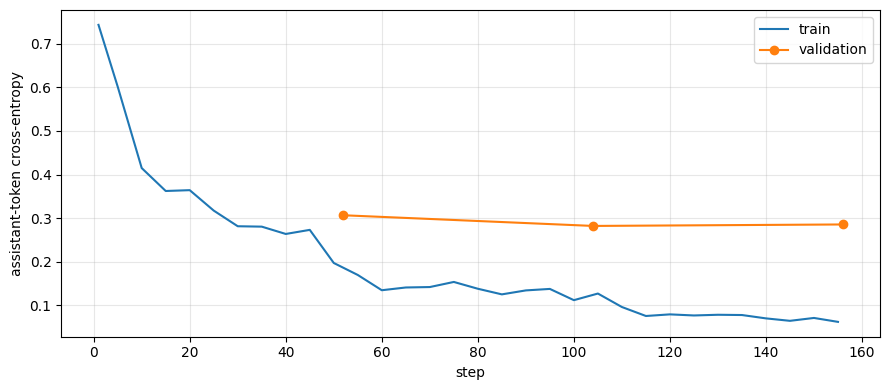

validation loss: 0.9213 -> 0.2855


In [15]:
history = pd.DataFrame(trainer.state.log_history)
history.to_csv(METRICS_DIR / "training_history.csv", index=False)
train_log = history.dropna(subset=["loss"])
eval_log = history.dropna(subset=["eval_loss"])

plt.figure(figsize=(9, 4))
plt.plot(train_log["step"], train_log["loss"], label="train")
plt.plot(eval_log["step"], eval_log["eval_loss"], marker="o", label="validation")
plt.xlabel("step")
plt.ylabel("assistant-token cross-entropy")
plt.grid(alpha=0.3)
plt.legend()
plt.tight_layout()
plt.savefig(METRICS_DIR / "loss.png", dpi=150)
plt.show()
print(f"validation loss: {initial_metrics['eval_loss']:.4f} -> {eval_log.iloc[-1]['eval_loss']:.4f}")

### Что показывает loss

При `assistant_only_loss=True` loss считается только по тексту и вызовам ассистента, включая
`<|im_end|>`. У сообщений `system` и `user`, схем функций, результатов `tool` и токенов заполнения
метка `-100`: модель их видит, но ошибка по ним не считается. Маска ставится до сдвига цели на токен.

Меньший loss на валидации означает, что эталонные ответы стали вероятнее, но не гарантирует
верные функции и аргументы. Поэтому отдельно проверяем вызовы и работу симулятора. Loss при
обучении и валидации считается в разных режимах; рост второго при падении первого может
говорить о переобучении.

## 5. Оценка на тест-сете

Eval loss показывает, насколько хорошо модель предсказывает ответы в валидационных диалогах, но не отвечает
на главный вопрос: вызывает ли она нужные функции. Проверим напрямую на `data/test_cases.jsonl`: 60 запросов к умному дому
(40 EN, 20 RU) с ожидаемыми вызовами.
- `tool_set_accuracy` — совпал набор вызванных функций (для запросов без вызова — модель ничего не вызвала);
- `exact_match` — совпали ещё и аргументы.

Битый `<tool_call>` или невалидный JSON — ошибка.

In [16]:
TOOL_CALL_PATTERN = re.compile(r"<tool_call>\s*(.*?)\s*</tool_call>", re.DOTALL)


def parse_tool_calls(text):
    """Вызовы {name, arguments} из ответа модели. None — формат нарушен."""
    blocks = TOOL_CALL_PATTERN.findall(text)
    if len(blocks) != text.count("<tool_call>"):
        return None
    try:
        calls = [json.loads(block) for block in blocks]
    except ValueError:
        return None
    if not all(isinstance(call, dict) and isinstance(call.get("name"), str) and isinstance(call.get("arguments"), dict) for call in calls):
        return None
    return [{"name": call["name"], "arguments": call["arguments"]} for call in calls]


ARGUMENT_DEFAULTS = {
    tool["function"]["name"]: {name: spec["default"] for name, spec in tool["function"]["parameters"]["properties"].items() if "default" in spec}
    for tool in SMART_HOME_TOOLS
}


def canonical(calls):
    """Вызовы как отсортированные строки; пропущенный аргумент со значением по умолчанию (quantity=1) равен явному."""
    filled = [{"name": c["name"], "arguments": {**ARGUMENT_DEFAULTS.get(c["name"], {}), **c["arguments"]}} for c in calls]
    return sorted(json.dumps(c, sort_keys=True) for c in filled)


def evaluate(model, tokenizer, cases):
    rows = []
    for case in cases:
        messages = case["messages"]
        if messages[0]["role"] != "system":
            messages = [{"role": "system", "content": SYSTEM_PROMPT}, *messages]
        output = generate(model, tokenizer, messages, SMART_HOME_TOOLS)
        calls = parse_tool_calls(output)
        tools_ok = calls is not None and {call["name"] for call in calls} == set(case["expected_tools"])
        rows.append({
            "id": case["id"], "lang": case["lang"], "output": output,
            "tools_ok": tools_ok,
            "args_ok": tools_ok and canonical(calls) == canonical(case["expected_calls"]),
        })
    return pd.DataFrame(rows)


def summarize(results):
    return results.groupby("lang").agg(tool_set_accuracy=("tools_ok", "mean"), exact_match=("args_ok", "mean"))

In [17]:
del trainer
gc.collect()
torch.cuda.empty_cache()
model.eval()

cases = read_jsonl(DATA_DIR / "test_cases.jsonl")
base_model = AutoModelForCausalLM.from_pretrained(
    MODEL_NAME, dtype=torch.bfloat16, attn_implementation="sdpa", local_files_only=True,
).to("cuda")
base_results = evaluate(base_model, tokenizer, cases)
del base_model
gc.collect()
torch.cuda.empty_cache()

del model
gc.collect()
torch.cuda.empty_cache()
tokenizer = AutoTokenizer.from_pretrained(OUTPUT_DIR, local_files_only=True)
model = AutoModelForCausalLM.from_pretrained(
    OUTPUT_DIR, dtype=torch.bfloat16, attn_implementation="sdpa", local_files_only=True,
).to("cuda").eval()
sft_results = evaluate(model, tokenizer, cases)
scores = pd.concat([
    summarize(base_results).assign(model="base"),
    summarize(sft_results).assign(model="sft"),
]).reset_index()[["model", "lang", "tool_set_accuracy", "exact_match"]]
predictions = pd.concat([
    base_results.assign(model="base"), sft_results.assign(model="sft"),
], ignore_index=True)
predictions.to_csv(METRICS_DIR / "test_predictions.csv", index=False)
scores.to_csv(METRICS_DIR / "eval_results.csv", index=False)
shutil.copy2(METRICS_DIR / "eval_results.csv", "outputs/eval_results.csv")
display(scores)
display(predictions.groupby("model")[["tools_ok", "args_ok"]].mean().rename(
    columns={"tools_ok": "tool_set_accuracy", "args_ok": "exact_match"},
))

,model,lang,tool_set_accuracy,exact_match
0,base,en,0.75,0.550
1,base,ru,0.75,0.200
2,sft,en,1.00,0.975
3,sft,ru,1.00,0.950


,tool_set_accuracy,exact_match
model,,
base,0.75,0.433333
sft,1.00,0.966667


### Результаты и ограничения

Запуск `full_sft_qwen25_05b_smarthome_v1`: все веса, три эпохи на H100, 55,7 секунды.
Loss на валидации снизился с 0,9213 до 0.2855;
Ниже результаты финальной модели. 

| Модель | Язык | Набор функций | Точное совпадение |
|---|---|---:|---:|
| До обучения | Английский (40) | 75,0% | 55,0% |
| До обучения | Русский (20) | 75,0% | 20,0% |
| После SFT | Английский (40) | 100,0% | 97,5% |
| После SFT | Русский (20) | 95,0% | 95,0% |

Всего на 60 запросах точных ответов стало 58 вместо 26, а верных наборов функций 59 вместо 45.
Остались две ошибки: в `en_14` таймер на 90 минут вместо 60, в `ru_04` отказ выставить
19 градусов на кухне. Малый тест не гарантирует такой же результат на новых запросах.

Все пять сценариев агента прошли проверку: одиночный и параллельные вызовы, изменение
температуры в спальне с 21 до 23, затем до 25 градусов, приветствие и неподдерживаемый запрос
без вызовов. Результаты функций и конечное состояние дома проверены.

Те же десять запросов: base-модель и обученная.

In [18]:
comparison["after_sft"] = [answer(model, tokenizer, prompt) for prompt in BASELINE_PROMPTS]
comparison.to_csv(METRICS_DIR / "before_after.csv", index=False)
display(comparison)

,prompt,base,after_sft
0,Turn on the kitchen light.,"<tool_call>\n{""name"": ""turn_light"", ""arguments"": {""room"": ""kitchen"", ""state"": ""on""}}\n</tool_call>","<tool_call>\n{""name"": ""turn_light"", ""arguments"": {""room"": ""kitchen"", ""state"": ""on""}}\n</tool_call>"
1,Set the bedroom to 23 degrees.,"<tool_call>\n{""name"": ""set_temperature"", ""arguments"": {""room"": ""bedroom"", ""value"": 23}}\n</tool_call>","<tool_call>\n{""name"": ""set_temperature"", ""arguments"": {""room"": ""bedroom"", ""value"": 23}}\n</tool_call>"
2,What is the state of the living room?,"<tool_call>\n{""name"": ""get_room_state"", ""arguments"": {""room"": ""living_room""}}\n</tool_call>","<tool_call>\n{""name"": ""get_room_state"", ""arguments"": {""room"": ""living_room""}}\n</tool_call>"
3,Add two cartons of milk to my shopping list.,"<tool_call>\n{""name"": ""add_to_shopping_list"", ""arguments"": {""item"": ""milk"", ""quantity"": 2}}\n</tool_call>","<tool_call>\n{""name"": ""add_to_shopping_list"", ""arguments"": {""item"": ""cartons of milk"", ""quantity"": 2}}\n</tool_call>"
4,Set a 10-minute timer labeled pasta.,"<tool_call>\n{""name"": ""set_timer"", ""arguments"": {""minutes"": 10, ""label"": ""pasta""}}\n</tool_call>","<tool_call>\n{""name"": ""set_timer"", ""arguments"": {""minutes"": 10, ""label"": ""pasta""}}\n</tool_call>"
5,Turn off the bedroom light and set its temperature to 20 degrees.,"<tool_call>\n{""name"": ""turn_light"", ""arguments"": {""room"": ""bedroom"", ""state"": ""off""}}\n</tool_call>\n<tool_call>\n{""name"": ""set_temperature"", ""arguments"": {""room"": ""bedroom"", ""value"": 20}}\n</tool...","<tool_call>\n{""name"": ""turn_light"", ""arguments"": {""room"": ""bedroom"", ""state"": ""off""}}\n</tool_call>\n<tool_call>\n{""name"": ""set_temperature"", ""arguments"": {""room"": ""bedroom"", ""value"": 20}}\n</tool..."
6,Turn off all lights.,"<tool_call>\n{""name"": ""turn_light"", ""arguments"": {""room"": ""all"", ""state"": ""off""}}\n</tool_call>","<tool_call>\n{""name"": ""turn_light"", ""arguments"": {""room"": ""kitchen"", ""state"": ""off""}}\n</tool_call>\n<tool_call>\n{""name"": ""turn_light"", ""arguments"": {""room"": ""bedroom"", ""state"": ""off""}}\n</tool_c..."
7,Hello!,How can I help you today?,"Hi! I can control lights and temperature in the kitchen, bedroom and living room, manage your shopping list and set timers. What would you like?"
8,Open the garage.,"<tool_call>\n{""name"": ""turn_light"", ""arguments"": {""room"": ""garage"", ""state"": ""on""}}\n</tool_call>","I can't control the garage. I can handle lights, temperature, your shopping list and timers."
9,Turn on the light.,"<tool_call>\n{""name"": ""turn_light"", ""arguments"": {""room"": ""living_room"", ""state"": ""on""}}\n</tool_call>",Which room's light should I turn on?


## 6. Агентный цикл · 2 балла

Модель печатает `<tool_call>`, но сама ничего не выполняет. Чтобы свет действительно включился,
нужен цикл: ответ модели → парсим вызовы → выполняем в симуляторе → результаты добавляем в историю
сообщениями `tool` → снова спрашиваем модель. Останавливаемся, когда модель ответила без вызовов.
`max_steps` защищает от бесконечных вызовов.

**Задание (2 балла).** Напишите `run_agent`: функция дописывает в `messages` реплики assistant
(с `tool_calls` в формате данных) и сообщения `tool`, пока модель не ответит текстом или не кончатся шаги.
Проверка — пять сценариев ниже: один вызов, два вызова за ход, относительное изменение температуры
(сначала нужно прочитать состояние), ответ без вызова и неподдерживаемый запрос. Оцениваем цикл, а не модель:
каждый вызов выполнен, результат попал в историю, состояние дома соответствует сделанным вызовам,
на неподдерживаемом запросе вызовов нет.

In [19]:
def run_agent(
    model: PreTrainedModel,
    tokenizer: PreTrainedTokenizerBase,
    home: SmartHome,
    messages: list[dict],
    max_steps: int = 4,
) -> None:
    if max_steps < 1:
        raise ValueError("`max_steps` must be positive")
    for _ in range(max_steps):
        output = generate(model, tokenizer, messages, SMART_HOME_TOOLS)
        calls = parse_tool_calls(output)
        if calls is None:
            messages.append({"role": "assistant", "content": output})
            raise ValueError("model returned malformed `tool_call` blocks")
        if not calls:
            messages.append({"role": "assistant", "content": output})
            return
        messages.append({
            "role": "assistant",
            "content": TOOL_CALL_PATTERN.sub("", output).strip(),
            "tool_calls": [{"type": "function", "function": call} for call in calls],
        })
        for call in calls:
            result = home.call(call["name"], call["arguments"])
            messages.append({
                "role": "tool", "name": call["name"],
                "content": json.dumps(result, ensure_ascii=False),
            })
    raise RuntimeError("agent exceeded `max_steps` without a final answer")

In [20]:
scenarios = [
    ["Turn on the kitchen light."],
    ["Turn on the kitchen light and set it to 23 degrees."],
    ["Make it two degrees warmer in the bedroom.", "Two more degrees."],
    ["Thanks!"],
    ["Open the garage."],
]
agent_results = []
for index, prompts in enumerate(scenarios):
    home = SmartHome()
    messages = [{"role": "system", "content": SYSTEM_PROMPT}]
    for prompt in prompts:
        messages.append({"role": "user", "content": prompt})
        run_agent(model, tokenizer, home, messages)
    tool_messages = [message for message in messages if message["role"] == "tool"]
    calls = [call["function"] for message in messages for call in message.get("tool_calls", [])]
    assert len(tool_messages) == len(calls), "every call must have a result"
    assert all("error" not in json.loads(message["content"]) for message in tool_messages)
    replay = SmartHome()
    for call, result in zip(calls, tool_messages):
        assert replay.call(call["name"], call["arguments"]) == json.loads(result["content"])
    assert replay.snapshot() == home.snapshot(), "state does not match executed calls"
    assert messages[-1]["role"] == "assistant" and not messages[-1].get("tool_calls")
    if index == 0:
        assert home.rooms["kitchen"]["light"] == "on"
    elif index == 1:
        assert home.rooms["kitchen"] == {"light": "on", "temperature": 23}
        assert any(len(message.get("tool_calls", [])) == 2 for message in messages)
    elif index == 2:
        assert home.rooms["bedroom"]["temperature"] == 25
        assert calls[0]["name"] == "get_room_state"
    else:
        assert not calls and home.snapshot() == SmartHome().snapshot()
    print("=" * 80)
    show_dialog(messages[1:])
    print(f"home: {json.dumps(home.snapshot(), ensure_ascii=False)}")
    agent_results.append({"prompts": prompts, "messages": messages, "state": home.snapshot(), "passed": True})
(METRICS_DIR / "agent_scenarios.json").write_text(json.dumps(agent_results, ensure_ascii=False, indent=2))
print(f"passed all {len(agent_results)} agent scenarios")

[user] Turn on the kitchen light.
[assistant] 
    -> turn_light({"room": "kitchen", "state": "on"})
[tool] {"room": "kitchen", "light": "on", "temperature": 21}
[assistant] The kitchen light is on now.
home: {"rooms": {"kitchen": {"light": "on", "temperature": 21}, "bedroom": {"light": "off", "temperature": 21}, "living_room": {"light": "off", "temperature": 20}}, "shopping_list": [], "timers": []}
[user] Turn on the kitchen light and set it to 23 degrees.
[assistant] 
    -> turn_light({"room": "kitchen", "state": "on"})
    -> set_temperature({"room": "kitchen", "value": 23})
[tool] {"room": "kitchen", "light": "on", "temperature": 21}
[tool] {"room": "kitchen", "light": "on", "temperature": 23}
[assistant] The kitchen light is on and it's set to 23 degrees.
home: {"rooms": {"kitchen": {"light": "on", "temperature": 23}, "bedroom": {"light": "off", "temperature": 21}, "living_room": {"light": "off", "temperature": 20}}, "shopping_list": [], "timers": []}
[user] Make it two degrees w

Тот же `run_agent` в чате: слева диалог и вызовы функций, справа состояние дома.
Попробуйте `Turn off all lights.`, `Add milk to my shopping list.`, `Set a 5-minute timer labeled tea.`

In [21]:
launch_chat(model, tokenizer, SmartHome(), run_agent)